# Use Function Transform (Log/Square Root) when:You have exponential or heavily right-skewed data (like housing prices or user click counts).Data values are strictly positive (for logs) and you want a quick, interpretable fix.

In [30]:
import pandas as pd 
import numpy as np 

import scipy.stats as stats 

import matplotlib.pyplot as plt 
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [31]:
df = pd.read_csv('train.csv',usecols=['Age','Fare','Survived'])

In [32]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [33]:
# df['Age'].fillna(df['Age'].mean(),inplace=True)

In [34]:
df.fillna({'Age':df['Age'].mean()},inplace=True)

In [35]:
df.sample()

,Survived,Age,Fare
609,1,40.0,153.4625


In [58]:
x =df.iloc[:,1:]
y = df.iloc[:,0]

In [59]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

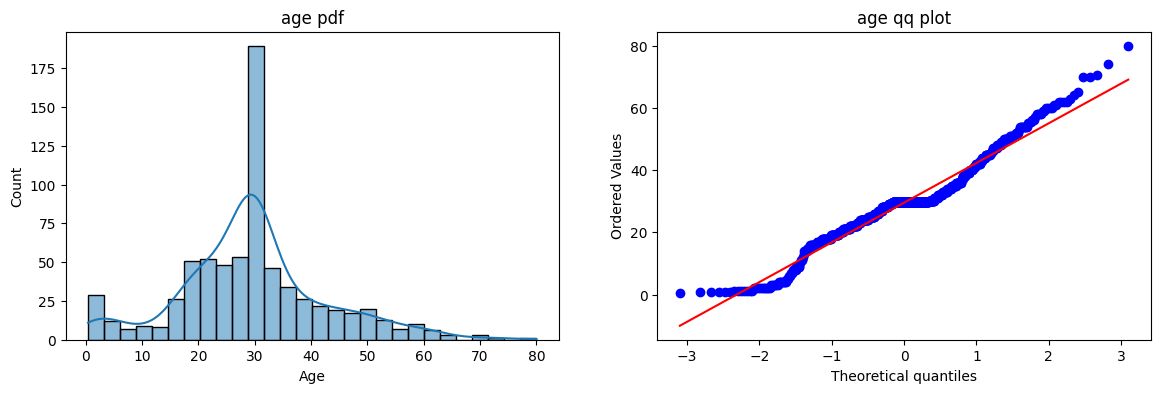

In [60]:
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.histplot(x_train['Age'],kde=True)
plt.title("age pdf")

plt.subplot(122)
stats.probplot(x_train['Age'],dist="norm",plot=plt)
plt.title('age qq plot')

plt.show()

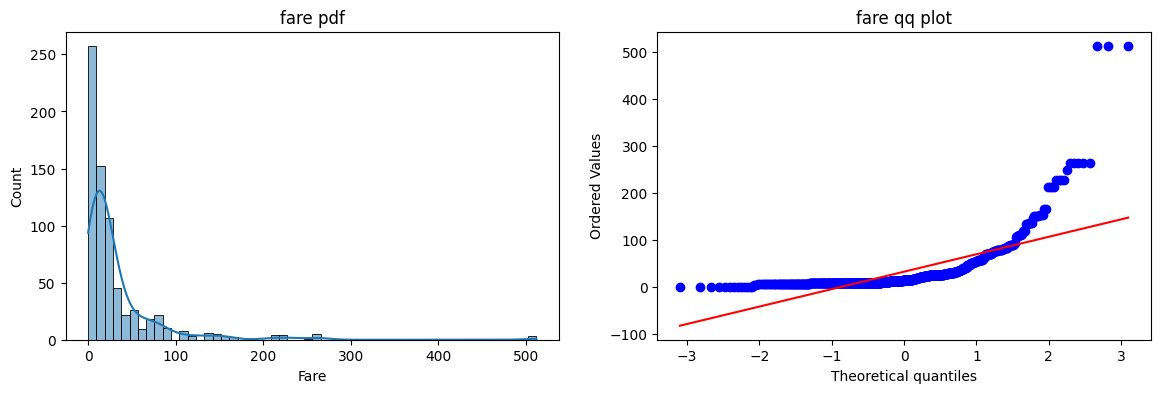

In [61]:
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.histplot(x_train['Fare'],kde=True)
plt.title("fare pdf")

plt.subplot(122)
stats.probplot(x_train['Fare'],dist="norm",plot=plt)
plt.title('fare qq plot')

plt.show()

In [62]:
x_train.columns.tolist()

['Age', 'Fare']

In [63]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

In [64]:
clf.fit(x_train,y_train)
clf2.fit(x_train,y_train)

y_pred = clf.predict(x_test)
y_pred1 = clf2.predict(x_test)

print("accuracy LR",accuracy_score(y_test,y_pred))
print("accuracy DT",accuracy_score(y_test,y_pred1))

accuracy LR 0.6480446927374302
accuracy DT 0.659217877094972


In [65]:
trf = FunctionTransformer(func=np.log1p)

In [66]:
x_train_trf = trf.fit_transform(x_train)
x_test_trf = trf.transform(x_test)

In [67]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

clf.fit(x_train_trf,y_train)
clf2.fit(x_train_trf,y_train)

y_pred = clf.predict(x_test_trf)
y_pred2= clf2.predict(x_test_trf)

print("accuracy LR",accuracy_score(y_test,y_pred))
print("accuracy DT",accuracy_score(y_test,y_pred2))

accuracy LR 0.6815642458100558
accuracy DT 0.6815642458100558


In [68]:
x_trf = trf.fit_transform(x)
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

print("LR", np.mean(cross_val_score(clf,x_trf,y,scoring='accuracy',cv=10))  )
print("DT", np.mean(cross_val_score(clf2,x_trf,y,scoring='accuracy',cv=10))  )

LR 0.678027465667915
DT 0.6610861423220974


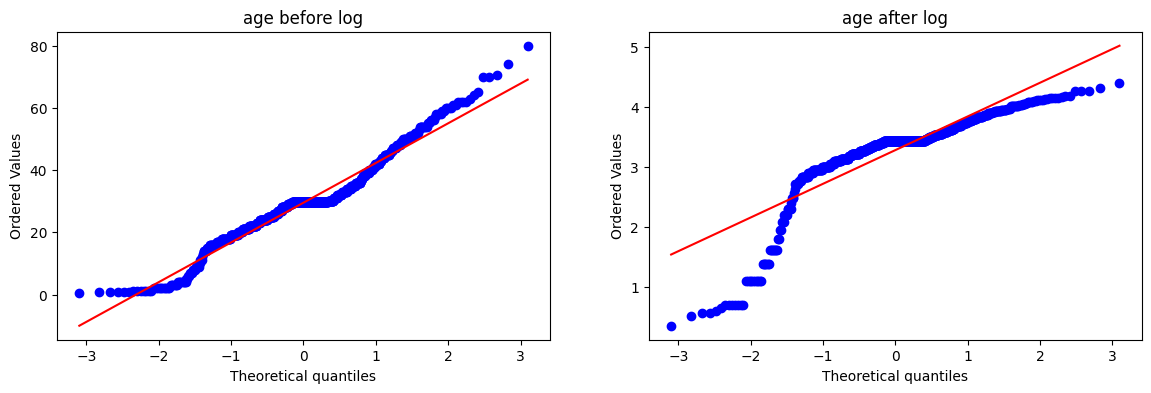

In [70]:
plt.figure(figsize=(14,4))
plt.subplot(121)
stats.probplot(x_train['Age'],dist="norm",plot=plt)
plt.title("age before log")

plt.subplot(122)
stats.probplot(x_train_trf['Age'],dist="norm",plot=plt)
plt.title('age after log')

plt.show()

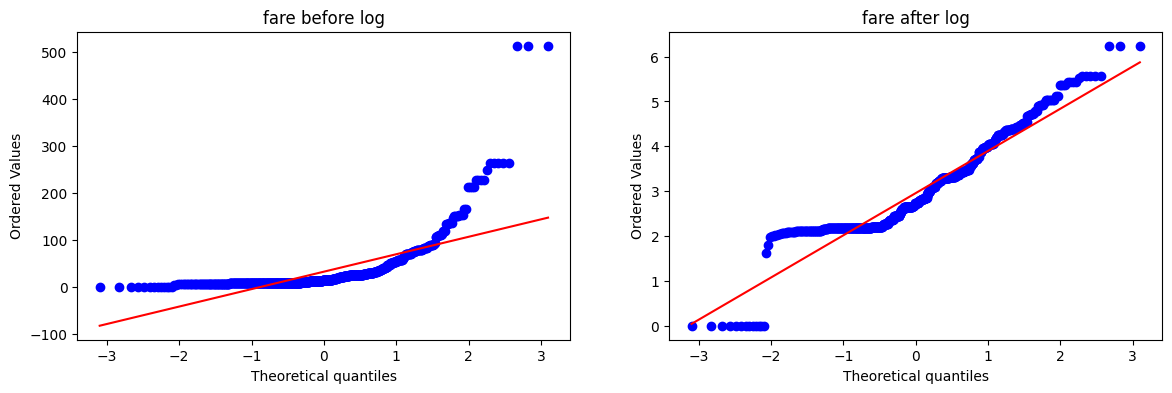

In [71]:
plt.figure(figsize=(14,4))
plt.subplot(121)
stats.probplot(x_train['Fare'],dist="norm",plot=plt)
plt.title("fare before log")

plt.subplot(122)
stats.probplot(x_train_trf['Fare'],dist="norm",plot=plt)
plt.title('fare after log')

plt.show()

In [72]:
trf3 = ColumnTransformer([('log',FunctionTransformer(np.log1p),['Fare'])],remainder= 'passthrough')

In [73]:
x_train_trf2 = trf3.fit_transform(x_train)
x_test_trf2 = trf3.transform(x_test)

In [74]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

clf.fit(x_train_trf2,y_train)
clf2.fit(x_train_trf2,y_train)

y_pred = clf.predict(x_test_trf2)
y_pred2= clf2.predict(x_test_trf2)

print("accuracy LR",accuracy_score(y_test,y_pred))
print("accuracy DT",accuracy_score(y_test,y_pred2))

accuracy LR 0.6703910614525139
accuracy DT 0.659217877094972


In [76]:
x_trf2 = trf3.fit_transform(x)
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

print("LR", np.mean(cross_val_score(clf,x_trf2,y,scoring='accuracy',cv=10))  )
print("DT", np.mean(cross_val_score(clf2,x_trf2,y,scoring='accuracy',cv=10))  )

LR 0.6712609238451936
DT 0.6621972534332085


In [78]:
def apply_trf(transform):
    x =df.iloc[:,1:]
    y = df.iloc[:,0]

    trf3 = ColumnTransformer([('log',FunctionTransformer(transform),['Fare'])],remainder= 'passthrough')

    x_trf2 = trf3.fit_transform(x)
    clf = LogisticRegression()
    print("LR", np.mean(cross_val_score(clf,x_trf2,y,scoring='accuracy',cv=10))  )

    plt.figure(figsize=(14,4))
    plt.subplot(121)
    stats.probplot(x_train['Fare'],dist="norm",plot=plt)
    plt.title("fare before log")
    
    plt.subplot(122)
    stats.probplot(x_train_trf['Fare'],dist="norm",plot=plt)
    plt.title('fare after log')
    
    plt.show()
    

LR 0.6589013732833957


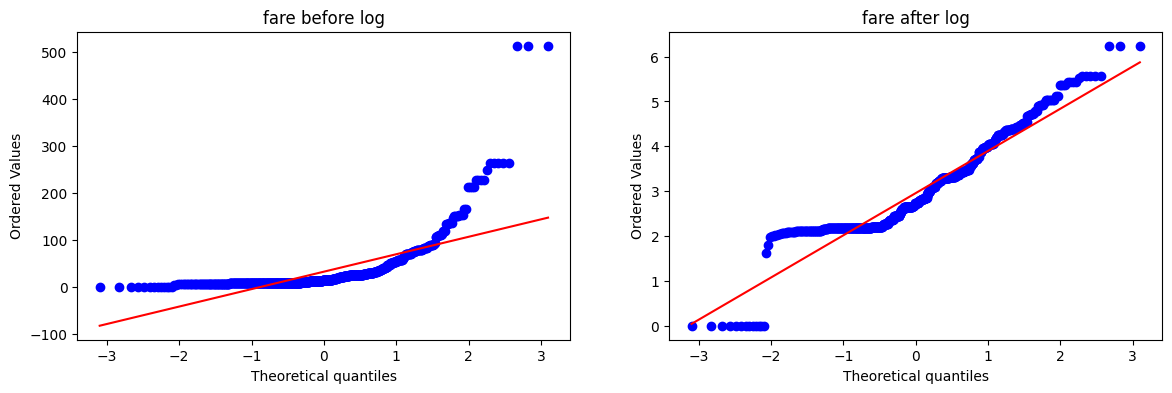

In [79]:
apply_trf(lambda x: x)